- Hvor mye bedre kan vi predikere strømforbruk når vi bruker historisk forbruk i tillegg til kalenderinformasjon?
- Hvilken modell gir de beste prognosene på nye data?

In [53]:
import pandas as pd
import numpy as np

# Kalenderbaserte features

In [54]:
df = pd.read_csv(
    "../data/consumption_selected.csv",
    sep=";",
    decimal=","
)

# Kalenderbaserte features
df["HOUR_SIN"] = np.sin(2 * np.pi * df["HOUR"] / 24)
df["HOUR_COS"] = np.cos(2 * np.pi * df["HOUR"] / 24)

df["MONTH_SIN"] = np.sin(2 * np.pi * (df["MONTH"] - 1) / 12)
df["MONTH_COS"] = np.cos(2 * np.pi * (df["MONTH"] - 1) / 12)

df["DAY_SIN"] = np.sin(2 * np.pi * df["DAY_OF_WEEK"] / 7)
df["DAY_COS"] = np.cos(2 * np.pi * df["DAY_OF_WEEK"] / 7)

df["IS_WEEKEND"] = (df["DAY_OF_WEEK"] >= 5).astype(int)

calendar_features = [
    "HOUR_SIN", "HOUR_COS",
    "MONTH_SIN", "MONTH_COS",
    "DAY_SIN", "DAY_COS",
    "IS_WEEKEND",
    "KOMMUNE",
    "FORBRUKSGRUPPE"
]

print(df[calendar_features].head())

   HOUR_SIN  HOUR_COS  MONTH_SIN  MONTH_COS   DAY_SIN  DAY_COS  IS_WEEKEND  \
0       0.0       1.0        0.5   0.866025  0.781831  0.62349           0   
1       0.0       1.0        0.5   0.866025  0.781831  0.62349           0   
2       0.0       1.0        0.5   0.866025  0.781831  0.62349           0   
3       0.0       1.0        0.5   0.866025  0.781831  0.62349           0   
4       0.0       1.0        0.5   0.866025  0.781831  0.62349           0   

  KOMMUNE FORBRUKSGRUPPE  
0    Alta     Forretning  
1    Alta       Industri  
2    Alta         Privat  
3  Bergen     Forretning  
4  Bergen       Industri  


Gjør dette slik at tallene blir mer som en klokke

# Historiske prediktorene

In [55]:
# Parse tidspunktene til norsk lokal tid
df["TIMESTAMP"] = (
    pd.to_datetime(df["STARTTID"], utc=True)
      .dt.tz_convert("Europe/Oslo")
)

df["DATE"] = df["TIMESTAMP"].dt.date
df["LOCAL_HOUR"] = df["TIMESTAMP"].dt.hour

keys = ["KOMMUNE", "FORBRUKSGRUPPE"]

# Daglige gjennomsnitt
daily = (
    df.groupby(keys + ["DATE"])["VOLUM_KWH"]
      .mean()
      .reset_index(name="DAILY_MEAN")
)

# Lag hjelpekolonne med dato
df["DATE_KEY"] = (
    df["TIMESTAMP"]
    .dt.tz_localize(None)
    .dt.normalize()
)

daily["DATE_KEY"] = pd.to_datetime(daily["DATE"])

# Gjennomsnitt tre kalenderdøgn tidligere
previous = daily[keys + ["DATE_KEY", "DAILY_MEAN"]].copy()
previous["DATE_KEY"] += pd.Timedelta(days=3)
previous = previous.rename(
    columns={"DAILY_MEAN": "MEAN_3D"}
)

df = df.merge(
    previous,
    on=keys + ["DATE_KEY"],
    how="left",
    validate="many_to_one"
)

# Timeforbruk 3 og 7 kalenderdøgn tidligere
for days in [3, 7]:
    history = df[
        keys + ["DATE_KEY", "LOCAL_HOUR", "VOLUM_KWH"]
    ].copy()

    history["DATE_KEY"] += pd.Timedelta(days=days)
    history = history.rename(
        columns={"VOLUM_KWH": f"LAG_{days}D"}
    )

    # Unngå mange-til-mange-merge ved gjentatt time
    # under overgang til vintertid
    history = (
        history.groupby(
            keys + ["DATE_KEY", "LOCAL_HOUR"],
            as_index=False
        )[f"LAG_{days}D"].mean()
    )

    df = df.merge(
        history,
        on=keys + ["DATE_KEY", "LOCAL_HOUR"],
        how="left",
        validate="many_to_one"
    )

print(
    df[[
        "KOMMUNE", "FORBRUKSGRUPPE",
        "DATE_KEY", "LOCAL_HOUR",
        "VOLUM_KWH", "LAG_3D",
        "LAG_7D", "MEAN_3D"
    ]].tail(10)
)

           KOMMUNE FORBRUKSGRUPPE   DATE_KEY  LOCAL_HOUR   VOLUM_KWH  \
1115960    Sunndal         Privat 2026-04-30          23    5328.694   
1115961     Tromsø     Forretning 2026-04-30          23   40554.563   
1115962     Tromsø       Industri 2026-04-30          23    9426.388   
1115963     Tromsø         Privat 2026-04-30          23   80151.881   
1115964  Trondheim     Forretning 2026-04-30          23   74044.931   
1115965  Trondheim       Industri 2026-04-30          23   38626.449   
1115966  Trondheim         Privat 2026-04-30          23  144997.318   
1115967      Årdal     Forretning 2026-04-30          23    1619.537   
1115968      Årdal       Industri 2026-04-30          23  390816.464   
1115969      Årdal         Privat 2026-04-30          23    4130.784   

             LAG_3D      LAG_7D        MEAN_3D  
1115960    6526.363    6372.506    6375.435042  
1115961   46270.853   49477.595   56299.576833  
1115962   10272.585   10054.141   11407.570542  
1115963   8

MEAN_3D = Hvordan var hele dagen for 3 dager siden?
LAG_3D = Hva var forbruket på samme time 3 dager siden?
LAG_7D = Hva var forbruket på samme time 1 uke siden?

For å gi modellen historikk slik at den lettere kan oppdage mønstre og lage bedre prognoser.

Prognosen for måldag D lages kl. 00.00 norsk tid på D−1. LAG_3D og MEAN_3D bruker D−3; LAG_7D bruker D−7. Tilgjengelighetskontrollen forutsetter én times publiseringsforsinkelse. Faktisk publiseringstid er ikke bekreftet, så tilgjengeligheten av målingene er fortsatt en forutsetning.

# Kontroll

In [56]:
lag_features = [
    "LAG_3D",
    "LAG_7D",
    "MEAN_3D"
]

print("Antall observasjoner:", len(df))

print("\nManglende historiske verdier:")
print(df[lag_features].isna().sum())

print("\nAndel manglende (%):")
print(
    (df[lag_features].isna().mean() * 100).round(2)
)

print("\nDuplikater per kommune, gruppe og tidspunkt:")
print(
    df.duplicated(
        subset=["KOMMUNE", "FORBRUKSGRUPPE", "TIMESTAMP"]
    ).sum()
)

Antall observasjoner: 1115970

Manglende historiske verdier:
LAG_3D     2310
LAG_7D     5190
MEAN_3D    2160
dtype: int64

Andel manglende (%):
LAG_3D     0.21
LAG_7D     0.47
MEAN_3D    0.19
dtype: float64

Duplikater per kommune, gruppe og tidspunkt:
0


In [57]:
lag_features = [
    "LAG_3D",
    "LAG_7D",
    "MEAN_3D"
]

# Finn observasjoner som mangler minst én lag feature
missing = df[df[lag_features].isna().any(axis=1)]

print("Manglende observasjoner per år:")
print(missing.groupby("YEAR").size())

print("\nManglende observasjoner per kommune:")
print(
    missing.groupby("KOMMUNE")
    .size()
    .sort_values(ascending=False)
)

print("\nAntall komplette observasjoner:")
print(df.dropna(subset=lag_features).shape[0])

Manglende observasjoner per år:
YEAR
2022    5100
2023      60
2024      60
2025      60
2026      60
dtype: int64

Manglende observasjoner per kommune:
KOMMUNE
Alta            534
Bergen          534
Bodø            534
Kristiansand    534
Oslo            534
Stavanger       534
Sunndal         534
Tromsø          534
Trondheim       534
Årdal           534
dtype: int64

Antall komplette observasjoner:
1110630


In [58]:
missing_dates = (
    df.loc[df[lag_features].isna().any(axis=1)]
      .groupby("DATE_KEY")
      .size()
)

print(missing_dates.to_string())


DATE_KEY
2022-02-01    720
2022-02-02    720
2022-02-03    720
2022-02-04    720
2022-02-05    720
2022-02-06    720
2022-02-07    720
2022-03-30     30
2022-04-03     30
2023-03-29     30
2023-04-02     30
2024-04-03     30
2024-04-07     30
2025-04-02     30
2025-04-06     30
2026-04-01     30
2026-04-05     30


Data som magler kommer av at vi ser tilbake i tid og sommertid

# Fjerner observasjoner med manglende historikk

In [59]:
# Fjern observasjoner med manglende historiske prediktorer
df_model = df.dropna(subset=lag_features).copy()

# Kontroller resultatet
print("Før:", len(df))
print("Etter:", len(df_model))
print("Fjernet:", len(df) - len(df_model))

print("\nManglende historiske verdier:")
print(df_model[lag_features].isna().sum())

Før: 1115970
Etter: 1110630
Fjernet: 5340

Manglende historiske verdier:
LAG_3D     0
LAG_7D     0
MEAN_3D    0
dtype: int64


# Train / Validation / Test Split

In [60]:
# Train: 2022–2024
train = df_model[df_model["YEAR"] <= 2024].copy()

# Validation: 2025
validation = df_model[df_model["YEAR"] == 2025].copy()

# Test: 2026
test = df_model[df_model["YEAR"] == 2026].copy()

# Kontroller oppdelingen
for name, subset in [
    ("Train", train),
    ("Validation", validation),
    ("Test", test)
]:
    print(
        f"{name}: {len(subset):,} observasjoner | "
        f"{subset['DATE_KEY'].min().date()} "
        f"til {subset['DATE_KEY'].max().date()}"
    )

print("\nTotalt:", len(train) + len(validation) + len(test))

Train: 761,580 observasjoner | 2022-02-08 til 2024-12-31
Validation: 262,740 observasjoner | 2025-01-01 til 2025-12-31
Test: 86,310 observasjoner | 2026-01-01 til 2026-04-30

Totalt: 1110630


In [61]:
# Modell A: Kun kalenderbaserte prediktorer
features_A = calendar_features.copy()

# Modell B: Kalender + historisk strømforbruk
features_B = calendar_features + lag_features

target = "VOLUM_KWH"

print("Modell A:", features_A)
print("\nModell B:", features_B)

Modell A: ['HOUR_SIN', 'HOUR_COS', 'MONTH_SIN', 'MONTH_COS', 'DAY_SIN', 'DAY_COS', 'IS_WEEKEND', 'KOMMUNE', 'FORBRUKSGRUPPE']

Modell B: ['HOUR_SIN', 'HOUR_COS', 'MONTH_SIN', 'MONTH_COS', 'DAY_SIN', 'DAY_COS', 'IS_WEEKEND', 'KOMMUNE', 'FORBRUKSGRUPPE', 'LAG_3D', 'LAG_7D', 'MEAN_3D']


A bruker kalender, kommune og forbruksgruppe.

B bruker det samme, pluss de tre historiske variablene.

In [62]:
# Modell A
X_train_A = train[features_A].copy()
X_val_A = validation[features_A].copy()
X_test_A = test[features_A].copy()

# Modell B
X_train_B = train[features_B].copy()
X_val_B = validation[features_B].copy()
X_test_B = test[features_B].copy()

# Samme target for begge modellene
y_train = train[target].copy()
y_val = validation[target].copy()
y_test = test[target].copy()

print("Modell A:", X_train_A.shape)
print("Modell B:", X_train_B.shape)
print("Target:", y_train.shape)

Modell A: (761580, 9)
Modell B: (761580, 12)
Target: (761580,)


Preprocessing

In [63]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Kategoriske prediktorer
categorical_features = [
    "KOMMUNE",
    "FORBRUKSGRUPPE"
]

# Numeriske prediktorer for hver modell
numerical_A = [
    col for col in features_A
    if col not in categorical_features
]

numerical_B = [
    col for col in features_B
    if col not in categorical_features
]

# Preprocessing for Modell A
preprocessor_A = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_A),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

# Preprocessing for Modell B
preprocessor_B = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_B),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

print("Numeriske variabler A:", numerical_A)
print("Numeriske variabler B:", numerical_B)
print("\nPreprocessing opprettet.")

Numeriske variabler A: ['HOUR_SIN', 'HOUR_COS', 'MONTH_SIN', 'MONTH_COS', 'DAY_SIN', 'DAY_COS', 'IS_WEEKEND']
Numeriske variabler B: ['HOUR_SIN', 'HOUR_COS', 'MONTH_SIN', 'MONTH_COS', 'DAY_SIN', 'DAY_COS', 'IS_WEEKEND', 'LAG_3D', 'LAG_7D', 'MEAN_3D']

Preprocessing opprettet.


Gjør kategorier om til tall og skalerer de

# Baseline A

In [64]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Gjennomsnitt fra treningsdataene
baseline_A = (
    train.groupby([
        "KOMMUNE",
        "FORBRUKSGRUPPE",
        "DAY_OF_WEEK",
        "HOUR"
    ])["VOLUM_KWH"]
    .mean()
    .rename("PREDICTION")
    .reset_index()
)

# Koble prediksjonene til valideringsdataene
val_baseline_A = validation.merge(
    baseline_A,
    on=["KOMMUNE", "FORBRUKSGRUPPE", "DAY_OF_WEEK", "HOUR"],
    how="left",
    validate="many_to_one"
)

# Kontroller at alle observasjoner fikk prediksjon
print("Manglende prediksjoner:",
      val_baseline_A["PREDICTION"].isna().sum())

# Evaluer
y_pred_A = val_baseline_A["PREDICTION"]

mae_A = mean_absolute_error(y_val, y_pred_A)
rmse_A = np.sqrt(mean_squared_error(y_val, y_pred_A))

print(f"Baseline A - MAE: {mae_A:,.2f} kWh")
print(f"Baseline A - RMSE: {rmse_A:,.2f} kWh")

Manglende prediksjoner: 0
Baseline A - MAE: 20,365.37 kWh
Baseline A - RMSE: 40,934.92 kWh


Baseline B

In [65]:
# Prediksjon = forbruk samme time uken før
y_pred_B = validation["LAG_7D"]

mae_B = mean_absolute_error(y_val, y_pred_B)
rmse_B = np.sqrt(mean_squared_error(y_val, y_pred_B))

print(f"Baseline B - MAE: {mae_B:,.2f} kWh")
print(f"Baseline B - RMSE: {rmse_B:,.2f} kWh")

Baseline B - MAE: 9,247.76 kWh
Baseline B - RMSE: 21,594.20 kWh


Opprette modell

In [66]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Modell A: Kalenderbaserte prediktorer
model_A = Pipeline([
    ("preprocessing", preprocessor_A),
    ("regression", LinearRegression())
])

# Modell B: Kalender + historisk forbruk
model_B = Pipeline([
    ("preprocessing", preprocessor_B),
    ("regression", LinearRegression())
])

print("Begge regresjonsmodellene er opprettet.")

Begge regresjonsmodellene er opprettet.


Trainig

In [67]:
# Tren Modell A
model_A.fit(X_train_A, y_train)

# Tren Modell B
model_B.fit(X_train_B, y_train)

print("Begge modellene er ferdig trent.")

Begge modellene er ferdig trent.


Evaluering på valideringsdata

In [68]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Prediksjoner på valideringsdata
pred_A = model_A.predict(X_val_A)
pred_B = model_B.predict(X_val_B)

# Sammenlign modellene
results = pd.DataFrame({
    "Model": ["Linear Regression A", "Linear Regression B"],
    "MAE": [
        mean_absolute_error(y_val, pred_A),
        mean_absolute_error(y_val, pred_B)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_val, pred_A)),
        np.sqrt(mean_squared_error(y_val, pred_B))
    ],
    "R2": [
        r2_score(y_val, pred_A),
        r2_score(y_val, pred_B)
    ]
})

print(results.round(3).to_string(index=False))

              Model       MAE       RMSE    R2
Linear Regression A 89739.109 133348.111 0.339
Linear Regression B  8934.311  18831.553 0.987


Undersøkelse av den store diffen

In [69]:
# Sammenlign lineær regresjon B med historisk baseline

comparison = pd.DataFrame({
    "Model": [
        "Baseline B (LAG_7D)",
        "Linear Regression B"
    ],
    "MAE": [
        mean_absolute_error(y_val, validation["LAG_7D"]),
        mean_absolute_error(y_val, pred_B)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_val, validation["LAG_7D"])),
        np.sqrt(mean_squared_error(y_val, pred_B))
    ],
    "R2": [
        r2_score(y_val, validation["LAG_7D"]),
        r2_score(y_val, pred_B)
    ]
})

print(comparison.round(3).to_string(index=False))


              Model      MAE      RMSE    R2
Baseline B (LAG_7D) 9247.763 21594.196 0.983
Linear Regression B 8934.311 18831.553 0.987


Evaluering av modellene per forbruksgruppe

In [70]:
# Lag evalueringsdatasett
evaluation = validation[
    ["KOMMUNE", "FORBRUKSGRUPPE", "VOLUM_KWH", "LAG_7D"]
].copy()

evaluation["PRED_A"] = pred_A
evaluation["PRED_B"] = pred_B

# Evaluer per forbruksgruppe
group_results = []

for group, subset in evaluation.groupby("FORBRUKSGRUPPE"):
    actual = subset["VOLUM_KWH"]

    for model_name, prediction in [
        ("Baseline B", subset["LAG_7D"]),
        ("Linear Regression A", subset["PRED_A"]),
        ("Linear Regression B", subset["PRED_B"])
    ]:
        group_results.append({
            "Group": group,
            "Model": model_name,
            "MAE": mean_absolute_error(actual, prediction),
            "RMSE": np.sqrt(mean_squared_error(actual, prediction)),
            "R2": r2_score(actual, prediction)
        })

group_results = pd.DataFrame(group_results)

print(
    group_results
    .sort_values(["Group", "MAE"])
    .round(3)
    .to_string(index=False)
)


     Group               Model        MAE       RMSE    R2
Forretning          Baseline B   6434.238  14639.308 0.984
Forretning Linear Regression B   7669.841  15751.917 0.982
Forretning Linear Regression A  61145.853  89179.150 0.420
  Industri Linear Regression B   7474.085  17633.615 0.993
  Industri          Baseline B   7839.502  20876.534 0.990
  Industri Linear Regression A 131886.361 180981.315 0.281
    Privat Linear Regression B  11659.006  22468.085 0.975
    Privat          Baseline B  13469.550  27364.007 0.962
    Privat Linear Regression A  76185.113 112418.855 0.362


Ridge Regression

In [71]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

# Ridge-modell med samme preprocessing som tidligere
ridge_B = Pipeline([
    ("preprocessing", preprocessor_B),
    ("regression", Ridge(alpha=1.0))
])

# Tren på 2022–2024
ridge_B.fit(X_train_B, y_train)

# Prediker 2025
pred_ridge_B = ridge_B.predict(X_val_B)

# Evaluer
print("Ridge B")
print(
    "MAE:",
    round(mean_absolute_error(y_val, pred_ridge_B), 3)
)
print(
    "RMSE:",
    round(np.sqrt(mean_squared_error(y_val, pred_ridge_B)), 3)
)
print(
    "R2:",
    round(r2_score(y_val, pred_ridge_B), 3)
)

Ridge B
MAE: 8934.362
RMSE: 18831.533
R2: 0.987


Random Forest

In [72]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Preprocessing uten skalering
rf_preprocessor_B = ColumnTransformer([
    ("num", "passthrough", numerical_B),
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

# Random Forest
rf_B = Pipeline([
    ("preprocessing", rf_preprocessor_B),
    ("regression", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest B opprettet.")

Random Forest B opprettet.


Trening og evaluring

In [73]:
# Tren modellen på 2022–2024
rf_B.fit(X_train_B, y_train)

# Prediker på 2025
pred_rf_B = rf_B.predict(X_val_B)

# Evaluer
print("Random Forest B")
print("MAE:", round(mean_absolute_error(y_val, pred_rf_B), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_val, pred_rf_B)), 3))
print("R2:", round(r2_score(y_val, pred_rf_B), 3))

Random Forest B
MAE: 7257.751
RMSE: 16564.082
R2: 0.99


Evaluer Random Forest per forbruksgruppe

In [74]:
# Legg til Random Forest-prediksjonene
evaluation["PRED_RF_B"] = pred_rf_B

# Sammenlign modellene per forbruksgruppe
rf_group_results = []

for group, subset in evaluation.groupby("FORBRUKSGRUPPE"):
    actual = subset["VOLUM_KWH"]

    for model_name, prediction in [
        ("Baseline B", subset["LAG_7D"]),
        ("Linear Regression B", subset["PRED_B"]),
        ("Random Forest B", subset["PRED_RF_B"])
    ]:
        rf_group_results.append({
            "Group": group,
            "Model": model_name,
            "MAE": mean_absolute_error(actual, prediction),
            "RMSE": np.sqrt(mean_squared_error(actual, prediction)),
            "R2": r2_score(actual, prediction)
        })

rf_group_results = pd.DataFrame(rf_group_results)

print(
    rf_group_results
    .sort_values(["Group", "MAE"])
    .round(3)
    .to_string(index=False)
)

     Group               Model       MAE      RMSE    R2
Forretning     Random Forest B  5134.079 11464.559 0.990
Forretning          Baseline B  6434.238 14639.308 0.984
Forretning Linear Regression B  7669.841 15751.917 0.982
  Industri     Random Forest B  6524.934 16653.506 0.994
  Industri Linear Regression B  7474.085 17633.615 0.993
  Industri          Baseline B  7839.502 20876.534 0.990
    Privat     Random Forest B 10114.239 20355.124 0.979
    Privat Linear Regression B 11659.006 22468.085 0.975
    Privat          Baseline B 13469.550 27364.007 0.962


Random Forest A

In [75]:
# Preprocessing for Random Forest A
rf_preprocessor_A = ColumnTransformer([
    ("num", "passthrough", numerical_A),
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

# Random Forest A
rf_A = Pipeline([
    ("preprocessing", rf_preprocessor_A),
    ("regression", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ))
])

# Tren modellen
rf_A.fit(X_train_A, y_train)

print("Random Forest A ferdig trent.")


Random Forest A ferdig trent.


Evaluering og validering A

In [76]:
# Prediksjon på valideringsdataene
pred_rf_A = rf_A.predict(X_val_A)

comparison_rf = pd.DataFrame({
    "Model": [
        "Linear Regression A",
        "Random Forest A",
        "Linear Regression B",
        "Random Forest B"
    ],
    "MAE": [
        mean_absolute_error(y_val, pred_A),
        mean_absolute_error(y_val, pred_rf_A),
        mean_absolute_error(y_val, pred_B),
        mean_absolute_error(y_val, pred_rf_B)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_val, pred_A)),
        np.sqrt(mean_squared_error(y_val, pred_rf_A)),
        np.sqrt(mean_squared_error(y_val, pred_B)),
        np.sqrt(mean_squared_error(y_val, pred_rf_B))
    ],
    "R2": [
        r2_score(y_val, pred_A),
        r2_score(y_val, pred_rf_A),
        r2_score(y_val, pred_B),
        r2_score(y_val, pred_rf_B)
    ]
})

print(comparison_rf.round(3).to_string(index=False))


              Model       MAE       RMSE    R2
Linear Regression A 89739.109 133348.111 0.339
    Random Forest A  9384.811  18852.797 0.987
Linear Regression B  8934.311  18831.553 0.987
    Random Forest B  7257.751  16564.082 0.990


Evaluering av Random Forest A og B per kommune

In [77]:
# Opprett evalueringsdata
municipality_eval = validation[
    ["KOMMUNE", "FORBRUKSGRUPPE", "VOLUM_KWH"]
].copy()

municipality_eval["PRED_RF_A"] = pred_rf_A
municipality_eval["PRED_RF_B"] = pred_rf_B

# Beregn MAE per kommune
municipality_results = []

for municipality, subset in municipality_eval.groupby("KOMMUNE"):
    actual = subset["VOLUM_KWH"]

    mae_A = mean_absolute_error(
        actual, subset["PRED_RF_A"]
    )

    mae_B = mean_absolute_error(
        actual, subset["PRED_RF_B"]
    )

    municipality_results.append({
        "Kommune": municipality,
        "MAE_A": mae_A,
        "MAE_B": mae_B,
        "Improvement_%": (mae_A - mae_B) / mae_A * 100
    })

municipality_results = pd.DataFrame(municipality_results)

print(
    municipality_results
    .sort_values("Improvement_%", ascending=False)
    .round(2)
    .to_string(index=False)
)


     Kommune    MAE_A    MAE_B  Improvement_%
       Årdal  3189.72  1256.15          60.62
     Sunndal  5009.20  2174.22          56.60
Kristiansand  6896.02  4377.49          36.52
   Stavanger  7351.90  5302.02          27.88
   Trondheim 13213.21 10681.75          19.16
      Bergen 13049.50 10755.06          17.58
      Tromsø  5217.93  4359.55          16.45
        Alta  2219.81  1860.60          16.18
        Oslo 34367.68 28936.09          15.80
        Bodø  3333.13  2874.57          13.76


Gradient Boosting B

In [78]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

gb_preprocessor_B = ColumnTransformer([
    ("num", "passthrough", numerical_B),
    ("cat", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), categorical_features)
])

gb_B = Pipeline([
    ("preprocessing", gb_preprocessor_B),
    ("regression", HistGradientBoostingRegressor(
        early_stopping=False,
        max_iter=200,
        max_leaf_nodes=31,
        learning_rate=0.1,
        random_state=42
    ))
])

print("Gradient Boosting B opprettet.")

Gradient Boosting B opprettet.


Trening og evaluering

In [79]:
# Tren på 2022–2024
gb_B.fit(X_train_B, y_train)

# Prediker på 2025
pred_gb_B = gb_B.predict(X_val_B)

# Evaluer
print("Gradient Boosting B")

print(
    "MAE:",
    round(mean_absolute_error(y_val, pred_gb_B), 3)
)

print(
    "RMSE:",
    round(np.sqrt(mean_squared_error(y_val, pred_gb_B)), 3)
)

print(
    "R2:",
    round(r2_score(y_val, pred_gb_B), 3)
)


Gradient Boosting B
MAE: 7369.746
RMSE: 16121.807
R2: 0.99


Kontroll av oppsett på prognose

In [80]:
# Velg en observasjon fra valideringsperioden
sample = validation.sample(1, random_state=42).iloc[0]

print("Kommune:", sample["KOMMUNE"])
print("Forbruksgruppe:", sample["FORBRUKSGRUPPE"])
print("Dato:", sample["DATE_KEY"])
print("Time:", sample["LOCAL_HOUR"])

print("\nFaktisk forbruk:", sample["VOLUM_KWH"])
print("LAG_3D:", sample["LAG_3D"])
print("LAG_7D:", sample["LAG_7D"])
print("MEAN_3D:", sample["MEAN_3D"])

# Finn den opprinnelige observasjonen tre døgn tidligere
previous_date = sample["DATE_KEY"] - pd.Timedelta(days=3)

historical = df[
    (df["KOMMUNE"] == sample["KOMMUNE"]) &
    (df["FORBRUKSGRUPPE"] == sample["FORBRUKSGRUPPE"]) &
    (df["DATE_KEY"] == previous_date) &
    (df["LOCAL_HOUR"] == sample["LOCAL_HOUR"])
]

print("\nFaktisk historisk observasjon:")
print(
    historical[["DATE_KEY", "LOCAL_HOUR", "VOLUM_KWH"]]
    .to_string(index=False)
)

Kommune: Årdal
Forbruksgruppe: Industri
Dato: 2025-11-17 00:00:00
Time: 18

Faktisk forbruk: 393028.716
LAG_3D: 388916.623
LAG_7D: 390310.812
MEAN_3D: 388785.15675

Faktisk historisk observasjon:
  DATE_KEY  LOCAL_HOUR  VOLUM_KWH
2025-11-14          18 388916.623


Visualisering av faktiske og predikerte verdier

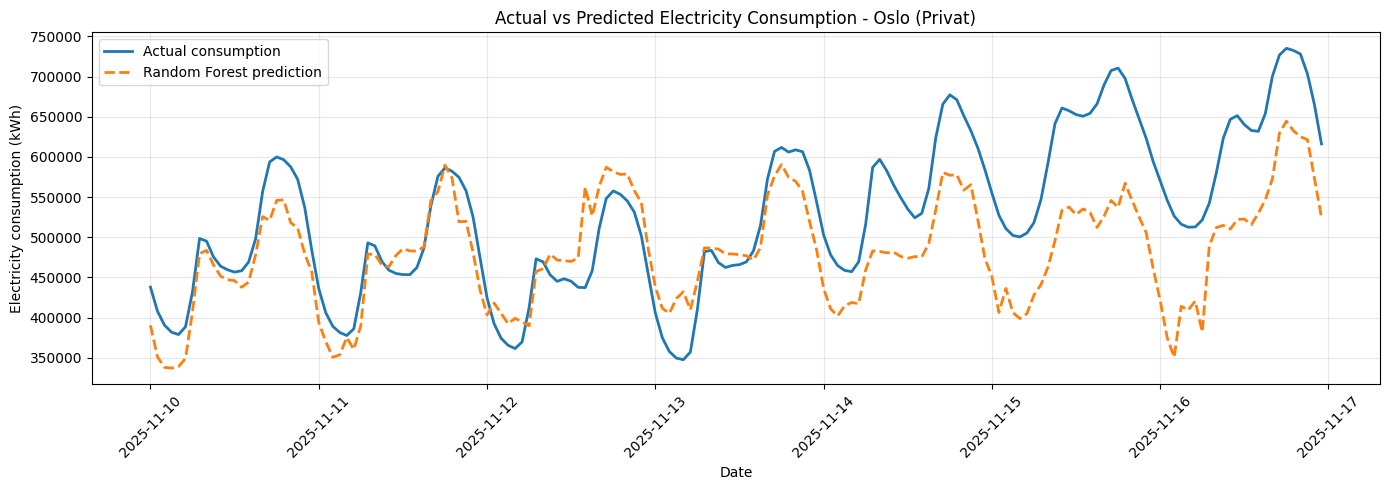

In [81]:
import matplotlib.pyplot as plt

# Bruk valideringsdataene og Random Forest-prediksjonene
plot_df = validation.copy()
plot_df["PRED_RF_B"] = pred_rf_B

# Velg kommune, forbruksgruppe og periode
subset = plot_df[
    (plot_df["KOMMUNE"] == "Oslo") &
    (plot_df["FORBRUKSGRUPPE"] == "Privat") &
    (plot_df["DATE_KEY"] >= "2025-11-10") &
    (plot_df["DATE_KEY"] < "2025-11-17")
].sort_values("TIMESTAMP")

# Plot
plt.figure(figsize=(14, 5))

plt.plot(
    subset["TIMESTAMP"],
    subset["VOLUM_KWH"],
    label="Actual consumption",
    linewidth=2
)

plt.plot(
    subset["TIMESTAMP"],
    subset["PRED_RF_B"],
    label="Random Forest prediction",
    linewidth=2,
    linestyle="--"
)

plt.title("Actual vs Predicted Electricity Consumption - Oslo (Privat)")
plt.xlabel("Date")
plt.ylabel("Electricity consumption (kWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Beregning av residualene

In [82]:

# Lag datasett for residualanalyse
residual_df = validation.copy()

# Legg til prediksjoner
residual_df["PREDICTED"] = pred_rf_B

# Beregn residualer
residual_df["RESIDUAL"] = (
    residual_df["VOLUM_KWH"] - residual_df["PREDICTED"]
)

print(residual_df["RESIDUAL"].describe())


count    262740.000000
mean       -181.443548
std       16563.119610
min     -486087.623353
25%       -2658.740177
50%         -57.986675
75%        2341.508222
max      335423.547447
Name: RESIDUAL, dtype: float64


Visualisering av residualene

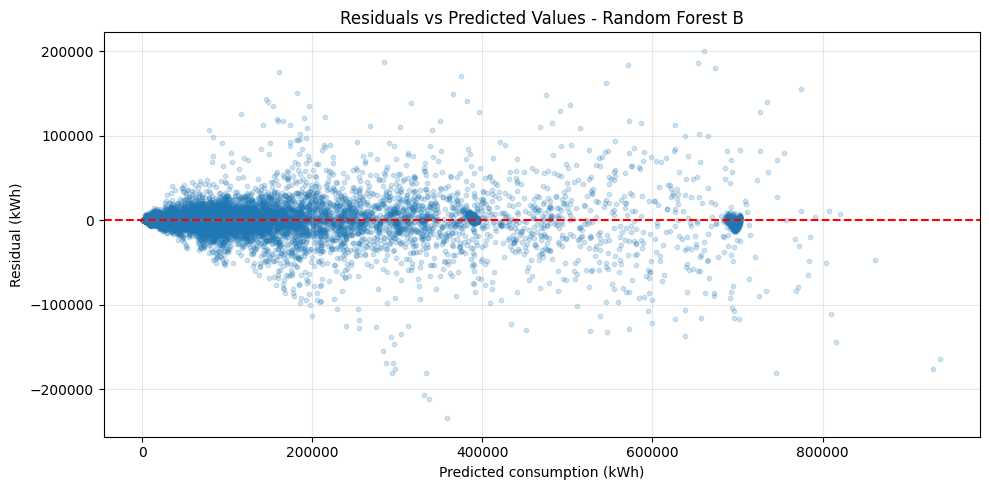

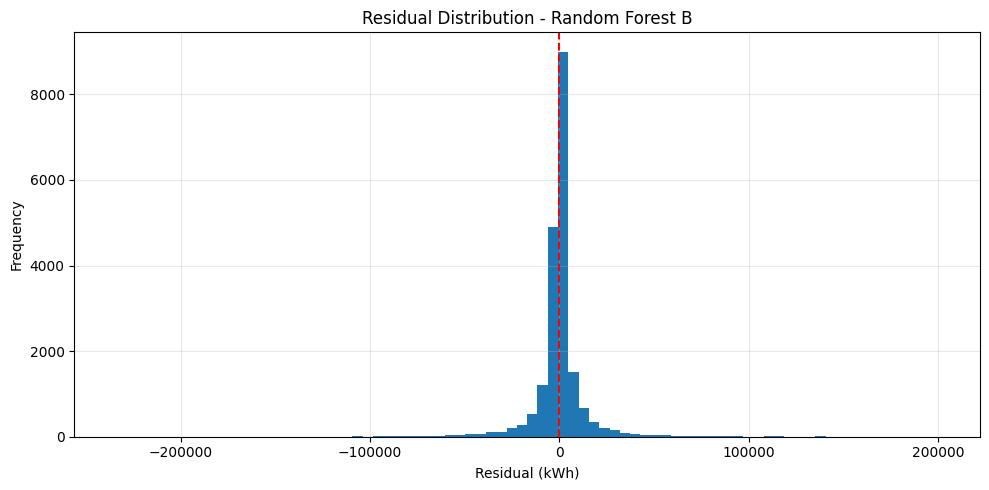

In [83]:
import matplotlib.pyplot as plt

# Tilfeldig utvalg for plotting
sample_residuals = residual_df.sample(
    n=min(20000, len(residual_df)),
    random_state=42
)

# Residualer mot predikert forbruk
plt.figure(figsize=(10, 5))

plt.scatter(
    sample_residuals["PREDICTED"],
    sample_residuals["RESIDUAL"],
    alpha=0.2,
    s=10
)

plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted consumption (kWh)")
plt.ylabel("Residual (kWh)")
plt.title("Residuals vs Predicted Values - Random Forest B")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Fordelingen av residualene
plt.figure(figsize=(10, 5))

plt.hist(
    sample_residuals["RESIDUAL"],
    bins=80
)

plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Residual (kWh)")
plt.ylabel("Frequency")
plt.title("Residual Distribution - Random Forest B")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Kontrollering av historiske prediktorer

In [84]:
# Kontroller de historiske prediktorene for 1000 tilfeldige rader
sample_check = validation.sample(
    n=1000,
    random_state=42
)

errors = []

for _, row in sample_check.iterrows():
    for days, feature in [
        (3, "LAG_3D"),
        (7, "LAG_7D")
    ]:
        historical = df[
            (df["KOMMUNE"] == row["KOMMUNE"]) &
            (df["FORBRUKSGRUPPE"] == row["FORBRUKSGRUPPE"]) &
            (df["DATE_KEY"] == row["DATE_KEY"] - pd.Timedelta(days=days)) &
            (df["LOCAL_HOUR"] == row["LOCAL_HOUR"])
        ]

        if len(historical) > 0:
            expected = historical["VOLUM_KWH"].mean()

            if not np.isclose(
                row[feature],
                expected,
                rtol=1e-9,
                atol=1e-6
            ):
                errors.append({
                    "Feature": feature,
                    "Date": row["DATE_KEY"],
                    "Expected": expected,
                    "Actual": row[feature]
                })

print("Antall avvik:", len(errors))
print(pd.DataFrame(errors).head())


Antall avvik: 0
Empty DataFrame
Columns: []
Index: []


Kontroll av MEAN_3D

In [85]:
# Kontroller MEAN_3D
sample_check = validation.sample(
    n=1000,
    random_state=42
)

errors = []

for _, row in sample_check.iterrows():

    previous_date = (
        row["DATE_KEY"] - pd.Timedelta(days=3)
    )

    historical = df[
        (df["KOMMUNE"] == row["KOMMUNE"]) &
        (df["FORBRUKSGRUPPE"] == row["FORBRUKSGRUPPE"]) &
        (df["DATE_KEY"] == previous_date)
    ]

    if len(historical) == 0:
        errors.append("Missing historical data")
        continue

    expected = historical["VOLUM_KWH"].mean()
    actual = row["MEAN_3D"]

    if not np.isclose(
        expected,
        actual,
        rtol=1e-9,
        atol=1e-6
    ):
        errors.append({
            "Date": row["DATE_KEY"],
            "Expected": expected,
            "Actual": actual
        })

print("Antall avvik:", len(errors))
print(pd.DataFrame(errors).head())


Antall avvik: 0
Empty DataFrame
Columns: []
Index: []


Kontroll av data leakage

In [86]:
# Kontroller historiske tidsgrenser
check = df_model.copy()

# Prognosetidspunkt for hver observasjon
check["FORECAST_TIME"] = check["DATE_KEY"] - pd.Timedelta(days=1)

# Tidspunkt for de historiske observasjonene
check["LAG_3D_TIME"] = (
    check["DATE_KEY"] - pd.Timedelta(days=3)
)

check["LAG_7D_TIME"] = (
    check["DATE_KEY"] - pd.Timedelta(days=7)
)

# Kontroll: historiske datoer skal være før prognosetidspunktet
invalid_3d = (
    check["LAG_3D_TIME"] >= check["FORECAST_TIME"]
).sum()

invalid_7d = (
    check["LAG_7D_TIME"] >= check["FORECAST_TIME"]
).sum()

print("Ugyldige LAG_3D:", invalid_3d)
print("Ugyldige LAG_7D:", invalid_7d)


Ugyldige LAG_3D: 0
Ugyldige LAG_7D: 0


Kontroll av SLUTTID

In [87]:
# Kontroller tidsgrensene for historiske inputvariabler.
# Publiseringsforsinkelsen er en antakelse, ikke dokumentert her.
publication_delay = pd.Timedelta(hours=1)

check = df_model[
    keys + ["DATE_KEY", "LOCAL_HOUR"]
].copy()

# Trekk fra ett kalenderdøgn før tidssonen settes.
check["FORECAST_TIME"] = (
    (check["DATE_KEY"] - pd.Timedelta(days=1))
    .dt.tz_localize("Europe/Oslo")
    .dt.tz_convert("UTC")
)

history = df[
    keys + ["DATE_KEY", "LOCAL_HOUR", "SLUTTID", "VOLUM_KWH"]
].copy()

history["MEASUREMENT_END"] = pd.to_datetime(
    history["SLUTTID"], utc=True
)

# Bare målinger som faktisk kan bidra til de historiske verdiene.
history = history.dropna(subset=["VOLUM_KWH"])

results = []

for feature, days, hourly in [
    ("LAG_3D", 3, True),
    ("LAG_7D", 7, True),
    ("MEAN_3D", 3, False),
]:
    join_keys = keys + ["DATE_KEY"]
    if hourly:
        join_keys = join_keys + ["LOCAL_HOUR"]

    # Ved gjentatt time brukes siste intervallslutt.
    # For døgnmiddel brukes siste intervallslutt i hele døgnet.
    lookup = (
        history.groupby(join_keys)["MEASUREMENT_END"]
        .max()
        .reset_index()
    )
    lookup["DATE_KEY"] += pd.Timedelta(days=days)

    audit = check.merge(
        lookup,
        on=join_keys,
        how="left",
        validate="many_to_one",
    )

    assumed_available = (
        audit["MEASUREMENT_END"] + publication_delay
    )

    results.append({
        "Variabel": feature,
        "Mangler sluttid": assumed_available.isna().sum(),
        "Etter prognosetidspunkt": (
            assumed_available > audit["FORECAST_TIME"]
        ).sum(),
        "Akkurat ved prognosetidspunkt": (
            assumed_available == audit["FORECAST_TIME"]
        ).sum(),
    })

availability_results = pd.DataFrame(results)
print(availability_results.to_string(index=False))

Variabel  Mangler sluttid  Etter prognosetidspunkt  Akkurat ved prognosetidspunkt
  LAG_3D                0                        0                              0
  LAG_7D                0                        0                              0
 MEAN_3D                0                        0                              0


Test ut ulike hyperparametere

In [88]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error
from sklearn.base import clone
import pandas as pd

# Hyperparametere vi vil undersøke
parameter_sets = [
    {"max_depth": 10, "min_samples_leaf": 5},
    {"max_depth": 15, "min_samples_leaf": 5},
    {"max_depth": 20, "min_samples_leaf": 5},
    {"max_depth": 20, "min_samples_leaf": 10},
    {"max_depth": None, "min_samples_leaf": 10}
]

rf_tuning_results = []

for params in parameter_sets:

    model = Pipeline([
        ("preprocessing", clone(rf_preprocessor_B)),
        ("regression", RandomForestRegressor(
            n_estimators=100,
            max_depth=params["max_depth"],
            min_samples_leaf=params["min_samples_leaf"],
            max_features=1.0,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train_B, y_train)
    predictions = model.predict(X_val_B)

    mae = mean_absolute_error(y_val, predictions)

    rf_tuning_results.append({
        "max_depth": params["max_depth"],
        "min_samples_leaf": params["min_samples_leaf"],
        "MAE": mae
    })

    print(params, "MAE:", round(mae, 2))

rf_tuning_results = pd.DataFrame(rf_tuning_results)

print("\nResultater:")
print(
    rf_tuning_results
    .sort_values("MAE")
    .round(2)
    .to_string(index=False)
)


{'max_depth': 10, 'min_samples_leaf': 5} MAE: 7689.71
{'max_depth': 15, 'min_samples_leaf': 5} MAE: 7257.75
{'max_depth': 20, 'min_samples_leaf': 5} MAE: 7204.48
{'max_depth': 20, 'min_samples_leaf': 10} MAE: 7190.26
{'max_depth': None, 'min_samples_leaf': 10} MAE: 7195.22

Resultater:
 max_depth  min_samples_leaf     MAE
      20.0                10 7190.26
       NaN                10 7195.22
      20.0                 5 7204.48
      15.0                 5 7257.75
      10.0                 5 7689.71


Optimalisere Gradient Boosting B

In [89]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
import pandas as pd

parameter_sets_gb = [
    {"max_iter": 100, "learning_rate": 0.1, "max_leaf_nodes": 31},
    {"max_iter": 200, "learning_rate": 0.1, "max_leaf_nodes": 31},
    {"max_iter": 300, "learning_rate": 0.1, "max_leaf_nodes": 31},
    {"max_iter": 300, "learning_rate": 0.05, "max_leaf_nodes": 31},
    {"max_iter": 300, "learning_rate": 0.1, "max_leaf_nodes": 63}
]

gb_tuning_results = []

for params in parameter_sets_gb:

    model = Pipeline([
        ("preprocessing", clone(gb_preprocessor_B)),
        ("regression", HistGradientBoostingRegressor(
            early_stopping=False,
            **params,
            random_state=42
        ))
    ])

    model.fit(X_train_B, y_train)
    predictions = model.predict(X_val_B)

    mae = mean_absolute_error(y_val, predictions)

    gb_tuning_results.append({
        **params,
        "MAE": mae
    })

    print(params, "MAE:", round(mae, 2))

gb_tuning_results = pd.DataFrame(gb_tuning_results)

print("\nResultater:")
print(
    gb_tuning_results
    .sort_values("MAE")
    .round(2)
    .to_string(index=False)
)


{'max_iter': 100, 'learning_rate': 0.1, 'max_leaf_nodes': 31} MAE: 7560.29
{'max_iter': 200, 'learning_rate': 0.1, 'max_leaf_nodes': 31} MAE: 7369.75
{'max_iter': 300, 'learning_rate': 0.1, 'max_leaf_nodes': 31} MAE: 7265.2
{'max_iter': 300, 'learning_rate': 0.05, 'max_leaf_nodes': 31} MAE: 7434.87
{'max_iter': 300, 'learning_rate': 0.1, 'max_leaf_nodes': 63} MAE: 7146.64

Resultater:
 max_iter  learning_rate  max_leaf_nodes     MAE
      300           0.10              63 7146.64
      300           0.10              31 7265.20
      200           0.10              31 7369.75
      300           0.05              31 7434.87
      100           0.10              31 7560.29


Kontroller av de to beste modellene

In [103]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Beste Random Forest
best_rf = Pipeline([
    ("preprocessing", clone(rf_preprocessor_B)),
    ("regression", RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=10,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ))
])

# Beste Gradient Boosting
best_gb = Pipeline([
    ("preprocessing", clone(gb_preprocessor_B)),
    ("regression", HistGradientBoostingRegressor(
        early_stopping=False,
        max_iter=300,
        learning_rate=0.1,
        max_leaf_nodes=63,
        random_state=42
    ))
])

# Tren på 2022–2024
best_rf.fit(X_train_B, y_train)
best_gb.fit(X_train_B, y_train)

# Prediker 2025
pred_best_rf = best_rf.predict(X_val_B)
pred_best_gb = best_gb.predict(X_val_B)

# Sammenlign
final_validation = pd.DataFrame({
    "Model": ["Random Forest B", "Gradient Boosting B"],
    "MAE": [
        mean_absolute_error(y_val, pred_best_rf),
        mean_absolute_error(y_val, pred_best_gb)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_val, pred_best_rf)),
        np.sqrt(mean_squared_error(y_val, pred_best_gb))
    ],
    "R2": [
        r2_score(y_val, pred_best_rf),
        r2_score(y_val, pred_best_gb)
    ]
})

print(final_validation.round(3).to_string(index=False))

              Model      MAE      RMSE   R2
    Random Forest B 7190.257 16488.823 0.99
Gradient Boosting B 7146.641 16153.297 0.99


In [104]:
from sklearn.base import clone

# Kalenderbasert preprocessing:
# samme behandling som B, men uten historiske forbruksvariabler.
gb_preprocessor_A = ColumnTransformer([
    ("num", "passthrough", numerical_A),
    ("cat", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
    ), categorical_features),
])

# To separate modeller med identiske modellinnstillinger
gb_comparison_A = clone(best_gb).set_params(
    preprocessing=gb_preprocessor_A,
    regression__early_stopping=False,
)

gb_comparison_B = clone(best_gb).set_params(
    regression__early_stopping=False,
)

# Kontroller at modellene bruker nøyaktig de samme radene
assert X_train_A.index.equals(X_train_B.index)
assert X_val_A.index.equals(X_val_B.index)
assert X_train_A.index.equals(y_train.index)
assert X_val_A.index.equals(y_val.index)

# Tren på 2022–2024
gb_comparison_A.fit(X_train_A, y_train)
gb_comparison_B.fit(X_train_B, y_train)

# Evaluer på de samme valideringsradene fra 2025
pred_gb_comparison_A = gb_comparison_A.predict(X_val_A)
pred_gb_comparison_B = gb_comparison_B.predict(X_val_B)

comparison_results = []

for name, model, predictions in [
    ("Gradient Boosting A", gb_comparison_A, pred_gb_comparison_A),
    ("Gradient Boosting B", gb_comparison_B, pred_gb_comparison_B),
]:
    comparison_results.append({
        "Modell": name,
        "MAE": mean_absolute_error(y_val, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_val, predictions)),
        "Iterasjoner": model.named_steps["regression"].n_iter_,
    })

gb_AB_results = pd.DataFrame(comparison_results)
print(gb_AB_results.round(2).to_string(index=False))

mae_A = gb_AB_results.loc[0, "MAE"]
mae_B = gb_AB_results.loc[1, "MAE"]

print(f"\nReduksjon i MAE med historikk: {mae_A - mae_B:,.2f} kWh")

if mae_A > 0:
    improvement = 100 * (mae_A - mae_B) / mae_A
    print(f"Relativ forbedring fra A til B: {improvement:.2f} %")

             Modell     MAE     RMSE  Iterasjoner
Gradient Boosting A 9122.75 18553.15          300
Gradient Boosting B 7146.64 16153.30          300

Reduksjon i MAE med historikk: 1,976.10 kWh
Relativ forbedring fra A til B: 21.66 %


Trene endelig modell

In [92]:
from sklearn.base import clone

# Kombiner train og validation
X_train_final = pd.concat(
    [X_train_B, X_val_B],
    axis=0
)

y_train_final = pd.concat(
    [y_train, y_val],
    axis=0
)

# Endelig modell med valgte hyperparametere
final_model = clone(best_gb)

# Tren på 2022–2025
final_model.fit(X_train_final, y_train_final)

print("Endelig Gradient Boosting-modell ferdig trent.")
print("Antall treningsobservasjoner:", len(X_train_final))


Endelig Gradient Boosting-modell ferdig trent.
Antall treningsobservasjoner: 1024320


In [105]:
import sklearn

print("scikit-learn-versjon:", sklearn.__version__)

results = []

for name, pipeline in [
    ("Gradient Boosting B", gb_B),
    ("Beste Gradient Boosting B", best_gb),
    ("Endelig modell", final_model),
]:
    model = pipeline.named_steps["regression"]

    results.append({
        "Modell": name,
        "early_stopping": model.early_stopping,
        "Early stopping aktivert": model.do_early_stopping_,
        "Valideringsandel": model.validation_fraction,
        "Maks iterasjoner": model.max_iter,
        "Faktiske iterasjoner": model.n_iter_,
        "Stoppet før maks": model.n_iter_ < model.max_iter,
        "Interne valideringsscore": len(model.validation_score_),
    })

print(pd.DataFrame(results).to_string(index=False))

scikit-learn-versjon: 1.8.0
                   Modell  early_stopping  Early stopping aktivert  Valideringsandel  Maks iterasjoner  Faktiske iterasjoner  Stoppet før maks  Interne valideringsscore
      Gradient Boosting B           False                    False               0.1               200                   200             False                         0
Beste Gradient Boosting B           False                    False               0.1               300                   300             False                         0
           Endelig modell           False                    False               0.1               300                   300             False                         0


Evaluering av testdataene

In [106]:
# Prediker testperioden fra 2026
pred_test = final_model.predict(X_test_B)

# Evaluer
test_mae = mean_absolute_error(y_test, pred_test)
test_rmse = np.sqrt(mean_squared_error(y_test, pred_test))
test_r2 = r2_score(y_test, pred_test)

print("FINAL TEST RESULTS (2026)")
print(f"MAE: {test_mae:,.3f} kWh")
print(f"RMSE: {test_rmse:,.3f} kWh")
print(f"R2: {test_r2:.4f}")


FINAL TEST RESULTS (2026)
MAE: 9,965.047 kWh
RMSE: 22,689.697 kWh
R2: 0.9854


Gjennomsnittlig residual (kWh): 1725.04
Median residual (kWh): -45.26
Andel underprediksjoner (%): 49.38
Andel overprediksjoner (%): 50.62

Feil etter forbruksnivå, fra lavest til høyest:
                          Antall  Gjennomsnittsforbruk  Gjennomsnittlig_residual       MAE
CONSUMPTION_LEVEL                                                                         
(1552.825, 21510.306]      21578               9171.59                   -378.91   1260.56
(21510.306, 71851.88]      21577              43463.16                  -1140.27   4783.63
(71851.88, 161094.674]     21577             106197.16                  -1465.84   9519.86
(161094.674, 1073136.78]   21578             409542.80                   9884.90  24295.87


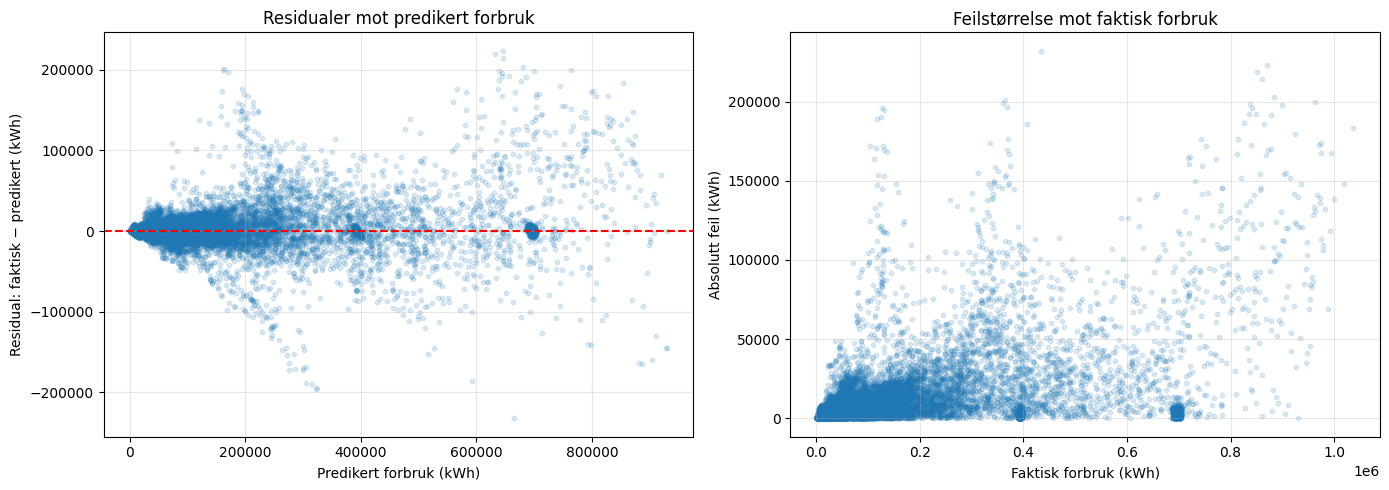

In [107]:
import matplotlib.pyplot as plt

# Faktisk og predikert forbruk i samme rekkefølge
gb_residuals = test[
    ["KOMMUNE", "FORBRUKSGRUPPE", "VOLUM_KWH"]
].copy()

gb_residuals["PREDICTED"] = pred_test

# Positiv residual = modellen underpredikerer
gb_residuals["RESIDUAL"] = (
    gb_residuals["VOLUM_KWH"] - gb_residuals["PREDICTED"]
)
gb_residuals["ABS_ERROR"] = gb_residuals["RESIDUAL"].abs()

print("Gjennomsnittlig residual (kWh):",
      round(gb_residuals["RESIDUAL"].mean(), 2))
print("Median residual (kWh):",
      round(gb_residuals["RESIDUAL"].median(), 2))
print("Andel underprediksjoner (%):",
      round(100 * (gb_residuals["RESIDUAL"] > 0).mean(), 2))
print("Andel overprediksjoner (%):",
      round(100 * (gb_residuals["RESIDUAL"] < 0).mean(), 2))

# Sammenlign feil ved ulike nivåer av faktisk forbruk
gb_residuals["CONSUMPTION_LEVEL"] = pd.qcut(
    gb_residuals["VOLUM_KWH"],
    q=4,
    duplicates="drop",
)

error_by_level = (
    gb_residuals.groupby("CONSUMPTION_LEVEL", observed=True)
    .agg(
        Antall=("RESIDUAL", "size"),
        Gjennomsnittsforbruk=("VOLUM_KWH", "mean"),
        Gjennomsnittlig_residual=("RESIDUAL", "mean"),
        MAE=("ABS_ERROR", "mean"),
    )
)

print("\nFeil etter forbruksnivå, fra lavest til høyest:")
print(error_by_level.round(2).to_string())

# Et utvalg gjør figurene lettere å lese
plot_sample = gb_residuals.sample(
    n=min(20000, len(gb_residuals)),
    random_state=42,
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    plot_sample["PREDICTED"],
    plot_sample["RESIDUAL"],
    alpha=0.15,
    s=10,
)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predikert forbruk (kWh)")
axes[0].set_ylabel("Residual: faktisk − predikert (kWh)")
axes[0].set_title("Residualer mot predikert forbruk")

axes[1].scatter(
    plot_sample["VOLUM_KWH"],
    plot_sample["ABS_ERROR"],
    alpha=0.15,
    s=10,
)
axes[1].set_xlabel("Faktisk forbruk (kWh)")
axes[1].set_ylabel("Absolutt feil (kWh)")
axes[1].set_title("Feilstørrelse mot faktisk forbruk")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Evaluering av forbruksgruppe

In [108]:
# Lag evalueringsdatasett
test_eval = test.copy()
test_eval["PREDICTED"] = pred_test

# Resultater per forbruksgruppe
group_test_results = []

for group, subset in test_eval.groupby("FORBRUKSGRUPPE"):
    actual = subset["VOLUM_KWH"]
    predicted = subset["PREDICTED"]

    group_test_results.append({
        "Group": group,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    })

group_test_results = pd.DataFrame(group_test_results)

print(group_test_results.round(3).to_string(index=False))


     Group       MAE      RMSE    R2
Forretning  6283.884 12916.868 0.991
  Industri  8921.924 22991.670 0.989
    Privat 14689.332 29137.684 0.978


Eval av koummne

In [109]:
municipality_test_results = []

for municipality, subset in test_eval.groupby("KOMMUNE"):
    actual = subset["VOLUM_KWH"]
    predicted = subset["PREDICTED"]

    municipality_test_results.append({
        "Kommune": municipality,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    })

municipality_test_results = pd.DataFrame(municipality_test_results)

print(
    municipality_test_results
    .sort_values("MAE", ascending=False)
    .round(3)
    .to_string(index=False)
)


     Kommune       MAE      RMSE    R2
        Oslo 44425.160 62320.164 0.932
      Bergen 16132.155 24007.240 0.960
   Trondheim 13036.557 18175.087 0.938
   Stavanger  6914.388 10356.759 0.964
Kristiansand  6128.526  9027.665 0.924
      Tromsø  4078.987  5740.058 0.976
        Bodø  3147.359  4536.659 0.969
        Alta  2585.509  3590.700 0.913
     Sunndal  1784.614  8440.357 0.999
       Årdal  1417.215  5596.050 0.999


Baseline vs. Gradient boosting på baseline

In [110]:
# Historisk baseline på testdataene
baseline_test = test["LAG_7D"]

# Beregn evalueringsmetrikker
test_comparison = pd.DataFrame({
    "Model": [
        "Historical Baseline",
        "Gradient Boosting B"
    ],
    "MAE": [
        mean_absolute_error(y_test, baseline_test),
        mean_absolute_error(y_test, pred_test)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_test)),
        np.sqrt(mean_squared_error(y_test, pred_test))
    ],
    "R2": [
        r2_score(y_test, baseline_test),
        r2_score(y_test, pred_test)
    ]
})

print(test_comparison.round(3).to_string(index=False))


              Model       MAE      RMSE    R2
Historical Baseline 12620.646 28642.545 0.977
Gradient Boosting B  9965.047 22689.697 0.985


Normalisert MAE per kommune

In [111]:
# Normalisert MAE per kommune
relative_results = []

for municipality, subset in test_eval.groupby("KOMMUNE"):

    actual = subset["VOLUM_KWH"]
    predicted = subset["PREDICTED"]

    mae = mean_absolute_error(actual, predicted)
    mean_consumption = actual.abs().mean()

    nmae = (mae / mean_consumption) * 100

    relative_results.append({
        "Kommune": municipality,
        "MAE_kWh": mae,
        "Mean_Consumption_kWh": mean_consumption,
        "NMAE_%": nmae
    })

relative_results = pd.DataFrame(relative_results)

print(
    relative_results
    .sort_values("NMAE_%", ascending=False)
    .round(2)
    .to_string(index=False)
)


     Kommune  MAE_kWh  Mean_Consumption_kWh  NMAE_%
        Alta  2585.51              22774.67   11.35
        Oslo 44425.16             430540.76   10.32
   Trondheim 13036.56             133224.58    9.79
      Bergen 16132.16             177484.99    9.09
        Bodø  3147.36              38865.96    8.10
   Stavanger  6914.39              97514.17    7.09
      Tromsø  4078.99              59697.63    6.83
Kristiansand  6128.53              90482.25    6.77
       Årdal  1417.22             134293.70    1.06
     Sunndal  1784.61             236073.61    0.76


NMAE per kommune og forbruksgruppe

In [112]:
# Normalisert MAE per kommune og forbruksgruppe
detailed_results = []

for (municipality, group), subset in test_eval.groupby(
    ["KOMMUNE", "FORBRUKSGRUPPE"]
):
    actual = subset["VOLUM_KWH"]
    predicted = subset["PREDICTED"]

    mae = mean_absolute_error(actual, predicted)
    mean_consumption = actual.abs().mean()

    nmae = (
        100 * mae / mean_consumption
        if mean_consumption > 0 else np.nan
    )

    detailed_results.append({
        "Kommune": municipality,
        "Forbruksgruppe": group,
        "MAE_kWh": mae,
        "Mean_Consumption_kWh": mean_consumption,
        "NMAE_%": nmae
    })

detailed_results = pd.DataFrame(detailed_results)

print(
    detailed_results
    .sort_values(["Kommune", "Forbruksgruppe"])
    .round(2)
    .to_string(index=False)
)


     Kommune Forbruksgruppe  MAE_kWh  Mean_Consumption_kWh  NMAE_%
        Alta     Forretning  2439.77              21754.16   11.22
        Alta       Industri  1343.87              10711.58   12.55
        Alta         Privat  3972.88              35858.26   11.08
      Bergen     Forretning 13799.96             188381.15    7.33
      Bergen       Industri  6952.91              36871.71   18.86
      Bergen         Privat 27643.60             307202.13    9.00
        Bodø     Forretning  2443.42              38372.99    6.37
        Bodø       Industri  1946.31              10583.44   18.39
        Bodø         Privat  5052.35              67641.45    7.47
Kristiansand     Forretning  4040.72              57810.88    6.99
Kristiansand       Industri  4852.26              92145.87    5.27
Kristiansand         Privat  9492.60             121490.01    7.81
        Oslo     Forretning 23374.39             471414.14    4.96
        Oslo       Industri 49565.88             172200.95   2

In [113]:
comparison_rows = []

for (municipality, group), subset in test_eval.groupby(
    ["KOMMUNE", "FORBRUKSGRUPPE"]
):
    actual = subset["VOLUM_KWH"]

    mae_model = mean_absolute_error(
        actual, subset["PREDICTED"]
    )
    mae_baseline = mean_absolute_error(
        actual, subset["LAG_7D"]
    )

    improvement = (
        100 * (mae_baseline - mae_model) / mae_baseline
        if mae_baseline > 0 else np.nan
    )

    comparison_rows.append({
        "Kommune": municipality,
        "Forbruksgruppe": group,
        "MAE_modell": mae_model,
        "MAE_baseline": mae_baseline,
        "Forbedring_prosent": improvement,
    })

baseline_comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("Forbedring_prosent", ascending=False)
)

print("Alle kombinasjoner, sortert etter relativ forbedring:")
print(baseline_comparison.round(2).to_string(index=False))

print("\nDe fem største relative forbedringene:")
print(baseline_comparison.head(5).round(2).to_string(index=False))

worse = baseline_comparison[
    baseline_comparison["MAE_modell"]
    > baseline_comparison["MAE_baseline"]
]

print(f"\nAntall kombinasjoner dårligere enn baseline: {len(worse)}")

if worse.empty:
    print("Ingen kombinasjoner har høyere MAE enn baseline.")
else:
    print(
        worse.sort_values("Forbedring_prosent")
        .round(2)
        .to_string(index=False)
    )

Alle kombinasjoner, sortert etter relativ forbedring:
     Kommune Forbruksgruppe  MAE_modell  MAE_baseline  Forbedring_prosent
      Tromsø         Privat     6579.57       9889.47               33.47
        Oslo     Forretning    23374.39      34172.97               31.60
   Stavanger         Privat    12068.32      17456.11               30.86
        Bodø         Privat     5052.35       7267.54               30.48
   Stavanger     Forretning     5792.27       8283.04               30.07
      Tromsø     Forretning     3344.30       4773.44               29.94
Kristiansand         Privat     9492.60      13215.53               28.17
   Trondheim     Forretning     6652.97       9249.33               28.07
   Trondheim         Privat    20019.13      27443.67               27.05
      Bergen         Privat    27643.60      37515.74               26.31
        Bodø     Forretning     2443.42       3274.58               25.38
Kristiansand     Forretning     4040.72       5396.88     

In [114]:
monthly_rows = []

for period, data, predictions in [
    ("Validering", validation, pred_best_gb),
    ("Uavhengig test", test, pred_test),
]:
    monthly_data = data[
        ["TIMESTAMP", "VOLUM_KWH", "LAG_7D"]
    ].copy()

    monthly_data["PREDICTED"] = predictions
    monthly_data["MONTH"] = (
        monthly_data["TIMESTAMP"].dt.strftime("%Y-%m")
    )

    for month, subset in monthly_data.groupby("MONTH"):
        actual = subset["VOLUM_KWH"]

        mae_model = mean_absolute_error(
            actual, subset["PREDICTED"]
        )
        mae_baseline = mean_absolute_error(
            actual, subset["LAG_7D"]
        )

        monthly_rows.append({
            "Periode": period,
            "Måned": month,
            "Antall": len(subset),
            "MAE_modell": mae_model,
            "MAE_baseline": mae_baseline,
            "Forbedring_prosent": (
                100 * (mae_baseline - mae_model) / mae_baseline
                if mae_baseline > 0 else np.nan
            ),
        })

monthly_results = pd.DataFrame(monthly_rows)

# Vis validering og test hver for seg
for period in ["Validering", "Uavhengig test"]:
    result = (
        monthly_results[monthly_results["Periode"] == period]
        .sort_values("Måned")
    )

    print(f"\n{period.upper()}")
    print(result.round(2).to_string(index=False))

    valid = result.dropna(subset=["Forbedring_prosent"])

    if not valid.empty:
        best = valid.loc[valid["Forbedring_prosent"].idxmax()]
        worst = valid.loc[valid["Forbedring_prosent"].idxmin()]

        print(
            f"\nStørst relativ forbedring: {best['Måned']} "
            f"({best['Forbedring_prosent']:.2f} %)"
        )
        print(
            f"Minst relativ forbedring: {worst['Måned']} "
            f"({worst['Forbedring_prosent']:.2f} %)"
        )


VALIDERING
   Periode   Måned  Antall  MAE_modell  MAE_baseline  Forbedring_prosent
Validering 2025-01   22320    12586.63      18464.30               31.83
Validering 2025-02   20160    10923.65      12962.47               15.73
Validering 2025-03   22290     8395.91      11449.74               26.67
Validering 2025-04   21540     8043.23      10377.90               22.50
Validering 2025-05   22320     6210.70       7576.22               18.02
Validering 2025-06   21600     4071.79       5238.10               22.27
Validering 2025-07   22320     2918.92       3730.41               21.75
Validering 2025-08   22320     3621.72       4671.55               22.47
Validering 2025-09   21600     4083.49       5318.77               23.22
Validering 2025-10   22350     5530.47       7241.24               23.63
Validering 2025-11   21600    10431.10      13833.97               24.60
Validering 2025-12   22320     9250.73      10404.99               11.09

Størst relativ forbedring: 2025-01 (31

## Actual vs. Predicted – Gradient Boosting B

Sluttmodellen, trent på 2022–2025, evalueres på testdata. Grafen viser Oslo Privat 12.–18. januar 2026 (lokal tid), en fast valgt uke. Endre kommune, forbruksgruppe og datogrenser i cellen for andre utsnitt.

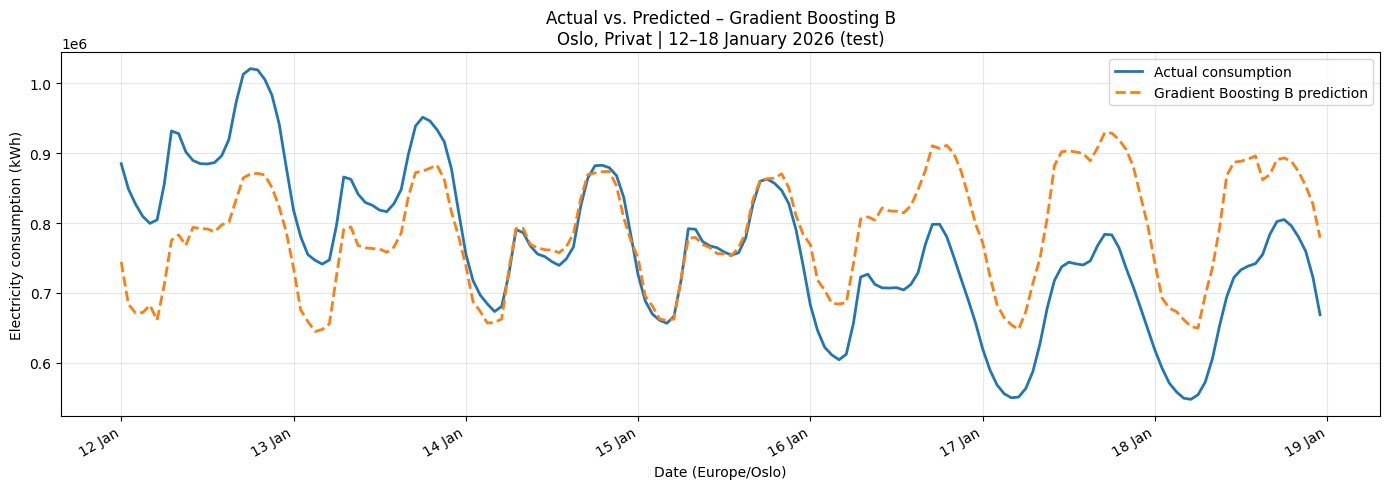

In [115]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

gb_time_series = test_eval.loc[
    (test_eval["KOMMUNE"] == "Oslo")
    & (test_eval["FORBRUKSGRUPPE"] == "Privat")
    & (test_eval["DATE_KEY"] >= "2026-01-12")
    & (test_eval["DATE_KEY"] < "2026-01-19")
].sort_values("TIMESTAMP")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(gb_time_series["TIMESTAMP"], gb_time_series["VOLUM_KWH"],
        label="Actual consumption", linewidth=2)
ax.plot(gb_time_series["TIMESTAMP"], gb_time_series["PREDICTED"],
        label="Gradient Boosting B prediction", linewidth=2, linestyle="--")
ax.set(title="Actual vs. Predicted – Gradient Boosting B\nOslo, Privat | 12–18 January 2026 (test)",
       xlabel="Date (Europe/Oslo)", ylabel="Electricity consumption (kWh)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b", tz=gb_time_series["TIMESTAMP"].dt.tz))
ax.legend()
ax.grid(alpha=0.3)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()


## NMAE per kommune og forbruksgruppe (Heatmap)

Testperiode: januar–april 2026. NMAE = 100 × MAE / gjennomsnittlig absolutt faktisk forbruk innen hver kommune–gruppe-kombinasjon. Lavere verdi er bedre; dette er ikke MAPE.

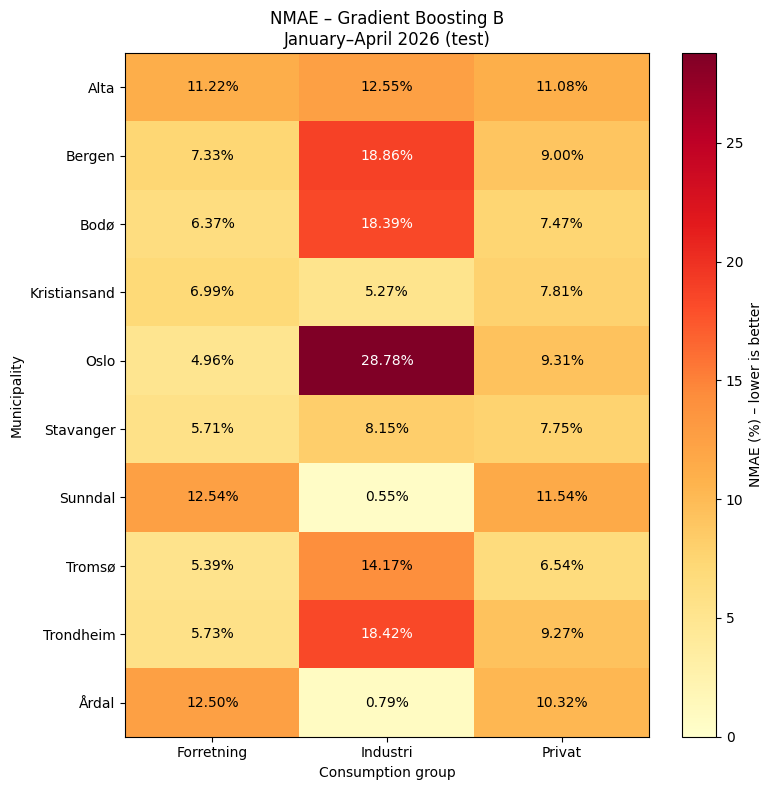

In [116]:
nmae_heatmap = (
    detailed_results.pivot(index="Kommune", columns="Forbruksgruppe", values="NMAE_%")
    .sort_index()
    .reindex(columns=["Forretning", "Industri", "Privat"])
)

fig, ax = plt.subplots(figsize=(8, 8))
heatmap = ax.imshow(nmae_heatmap.to_numpy(), cmap="YlOrRd", vmin=0, aspect="auto")
ax.set_xticks(range(len(nmae_heatmap.columns)), labels=nmae_heatmap.columns)
ax.set_yticks(range(len(nmae_heatmap.index)), labels=nmae_heatmap.index)
ax.set(title="NMAE – Gradient Boosting B\nJanuary–April 2026 (test)",
       xlabel="Consumption group", ylabel="Municipality")
for row in range(len(nmae_heatmap.index)):
    for col in range(len(nmae_heatmap.columns)):
        value = nmae_heatmap.iloc[row, col]
        ax.text(col, row, f"{value:.2f}%", ha="center", va="center",
                color="white" if heatmap.norm(value) > 0.6 else "black")
fig.colorbar(heatmap, ax=ax, label="NMAE (%) – lower is better")
fig.tight_layout()
plt.show()


## Monthly MAE – Gradient Boosting vs. Baseline

Testresultatene holdes atskilt fra validering. Stolpene viser sluttmodellen mot sesongnaiv baseline (`LAG_7D`) for hver av de fire testmånedene.

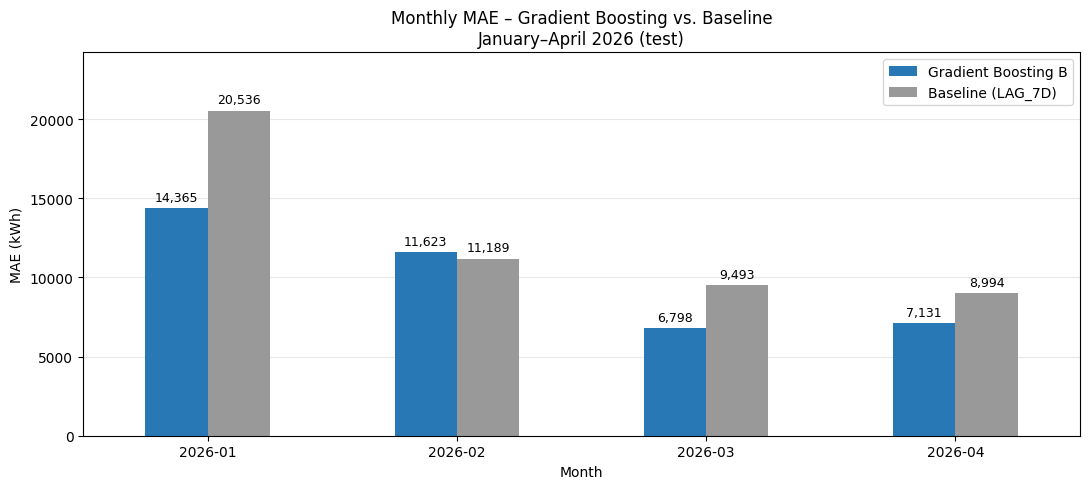

In [117]:
test_monthly_mae = (
    monthly_results.loc[monthly_results["Periode"] == "Uavhengig test"]
    .sort_values("Måned")
    .set_index("Måned")[["MAE_modell", "MAE_baseline"]]
    .rename(columns={"MAE_modell": "Gradient Boosting B", "MAE_baseline": "Baseline (LAG_7D)"})
)

ax = test_monthly_mae.plot.bar(figsize=(11, 5), color=["#2878B5", "#999999"], rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3, fontsize=9)
ax.set(title="Monthly MAE – Gradient Boosting vs. Baseline\nJanuary–April 2026 (test)",
       xlabel="Month", ylabel="MAE (kWh)")
ax.set_ylim(0, test_monthly_mae.to_numpy().max() * 1.18)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend()
ax.figure.tight_layout()
plt.show()


## Model Comparison – Validation MAE

Alle modellene trenes på 2022–2024 og evalueres på 2025. A bruker kalender, kommune og forbruksgruppe; B bruker også historisk forbruk. Random Forest B og Gradient Boosting B vises med de beste undersøkte innstillingene. Sluttmodellens testresultater inngår ikke her.

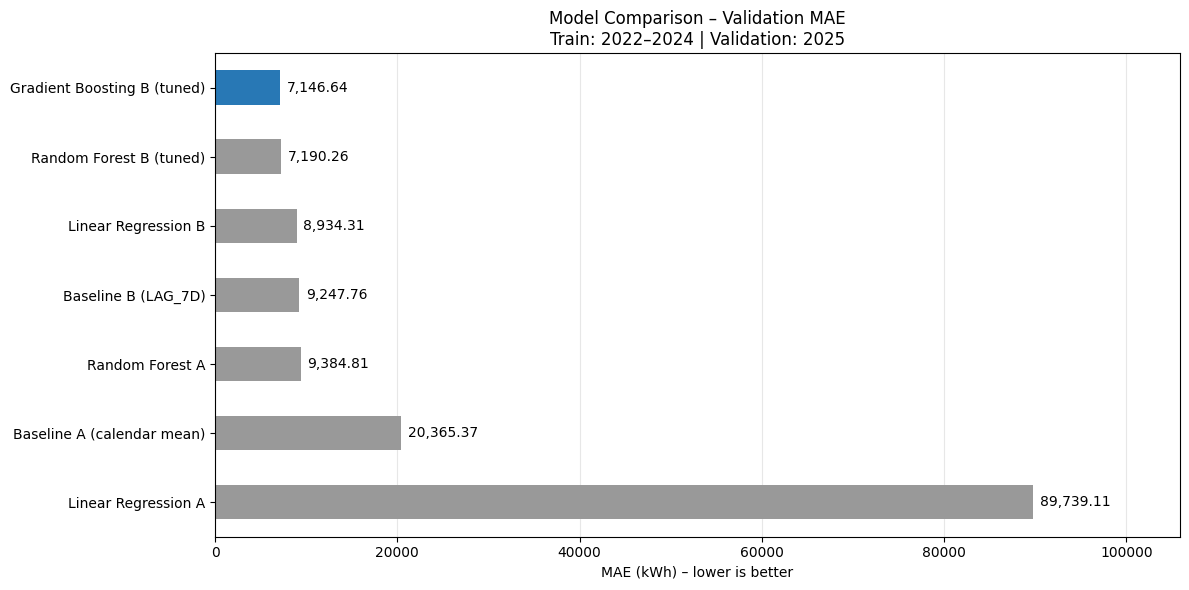

In [118]:
validation_mae_plot = pd.Series({
    "Baseline A (calendar mean)": mean_absolute_error(y_val, val_baseline_A["PREDICTION"]),
    "Baseline B (LAG_7D)": mean_absolute_error(y_val, validation["LAG_7D"]),
    "Linear Regression A": mean_absolute_error(y_val, pred_A),
    "Linear Regression B": mean_absolute_error(y_val, pred_B),
    "Random Forest A": mean_absolute_error(y_val, pred_rf_A),
    "Random Forest B (tuned)": mean_absolute_error(y_val, pred_best_rf),
    "Gradient Boosting B (tuned)": mean_absolute_error(y_val, pred_best_gb),
}, name="MAE").sort_values()

ax = validation_mae_plot.plot.barh(figsize=(12, 6), color=[
    "#2878B5" if name == "Gradient Boosting B (tuned)" else "#999999"
    for name in validation_mae_plot.index
])
ax.invert_yaxis()
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.2f}", padding=5)
ax.set(title="Model Comparison – Validation MAE\nTrain: 2022–2024 | Validation: 2025",
       xlabel="MAE (kWh) – lower is better", ylabel="")
ax.set_xlim(0, validation_mae_plot.max() * 1.18)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.figure.tight_layout()
plt.show()
